In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
a = pd.read_excel('superstore_unclean.xlsx')
a.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,2046,US-2023-133592,2023-12-31,2024-01-07,Standard Class,KM-16375,Katherine Murray,Home Office,United States,Providence,...,2908,East,OFF-PA-10003228,Office Supplies,Paper,Xerox 1917,195.64,4,0.0,91.9508
1,4701,US-2025-101525,2025-05-01,2025-05-04,Second Class,CM-12235,Chris McAfee,Consumer,United States,Little Rock,...,72209,South,OFF-PA-10001497,Office Supplies,Paper,Xerox 1914,109.92,2,0.0,53.8608
2,4964,US-2025-167472,2025-06-06,2025-06-07,First Class,CK-12595,Clytie Kelty,Consumer,United States,Little Rock,...,72209,South,TEC-AC-10003174,Technology,Accessories,Plantronics S12 Corded Telephone Headset System,323.37,3,0.0,129.3480
3,34,US-2023-103366,2023-01-15,2023-01-17,First Class,EH-13990,Erica Hackney,Consumer,United States,Roswell,...,30076,South,TEC-AC-10003628,Technology,Accessories,Logitech 910-002974 M325 Wireless Mouse for We...,149.95,5,0.0,65.9780
4,2927,US-2024-124219,2024-08-07,2024-08-08,First Class,KW-16570,Kelly Williams,Consumer,United States,Kirkwood,...,63122,Central,FUR-FU-10000305,Furniture,Furnishings,"Tenex V2T-RE Standard Weight Series Chair Mat,...",212.94,3,0.0,34.0704


In [3]:
a.to_csv('superstore_unclean.csv', index=False)

## 2(a) -- Load & Inspect the Data

In [4]:
df = pd.read_csv('superstore_unclean.csv')
df.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,2046,US-2023-133592,2023-12-31,2024-01-07,Standard Class,KM-16375,Katherine Murray,Home Office,United States,Providence,...,2908,East,OFF-PA-10003228,Office Supplies,Paper,Xerox 1917,195.64,4,0.0,91.9508
1,4701,US-2025-101525,2025-05-01,2025-05-04,Second Class,CM-12235,Chris McAfee,Consumer,United States,Little Rock,...,72209,South,OFF-PA-10001497,Office Supplies,Paper,Xerox 1914,109.92,2,0.0,53.8608
2,4964,US-2025-167472,2025-06-06,2025-06-07,First Class,CK-12595,Clytie Kelty,Consumer,United States,Little Rock,...,72209,South,TEC-AC-10003174,Technology,Accessories,Plantronics S12 Corded Telephone Headset System,323.37,3,0.0,129.3480


In [5]:
df.shape

(10214, 21)

### NOTE : No. of rows before cleaning -- 10,214

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10214 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10214 non-null  int64  
 1   Order ID        10214 non-null  object 
 2   Order Date      10214 non-null  object 
 3   Ship Date       10214 non-null  object 
 4   Ship Mode       10214 non-null  object 
 5   Customer ID     10214 non-null  object 
 6   Customer Name   10214 non-null  object 
 7   Segment         10214 non-null  object 
 8   Country/Region  10214 non-null  object 
 9   City            10214 non-null  object 
 10  State/Province  10214 non-null  object 
 11  Postal Code     10184 non-null  object 
 12  Region          10214 non-null  object 
 13  Product ID      10214 non-null  object 
 14  Category        10214 non-null  object 
 15  Sub-Category    10214 non-null  object 
 16  Product Name    10214 non-null  object 
 17  Sales           10194 non-null 

In [7]:
# The columns which are stored as text (object) when they should be numbers or dates -- Order Date, Ship Date, Postal Code

In [8]:
df.describe()

,Row ID,Sales,Quantity,Discount,Profit
count,10214.000000,10194.000000,10214.000000,10214.000000,10214.000000
mean,5096.372528,228.197158,3.781868,0.155452,28.641109
std,2943.754048,619.919582,2.244482,0.206313,232.241551
min,1.000000,0.440000,-8.000000,0.000000,-6599.978000
25%,2547.250000,17.248000,2.000000,0.000000,1.753775
50%,5095.500000,53.930000,3.000000,0.200000,8.687750
75%,7645.750000,209.001000,5.000000,0.200000,29.282175
max,10194.000000,22638.480000,14.000000,0.800000,8399.976000


## 2(b) -- Clean the Data

In [9]:
## STEP 1
df.duplicated().sum()

np.int64(20)

In [10]:
df = df.drop_duplicates()

df.duplicated().sum()

np.int64(0)

In [11]:
df['Sales'].dtype

dtype('float64')

In [12]:
df['Order Date'].dtype , df['Ship Date'].dtype

(dtype('O'), dtype('O'))

In [13]:
## STEP 2 
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='mixed', errors='coerce')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10194 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10164 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194 non-null  object        
 15  Sub-Cat

In [15]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State/Province     0
Postal Code       30
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales             20
Quantity           0
Discount           0
Profit             0
dtype: int64

In [16]:
## STEP 3
df.dropna(inplace=True)

In [17]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [18]:
## STEP 4
df['Ship Mode'].value_counts()

Ship Mode
Standard Class    5731
Second Class      1838
First Class       1449
Same Day           517
standard class     241
STANDARD CLASS     119
second class        89
first class         56
SECOND CLASS        41
FIRST CLASS         34
same day            19
SAME DAY            10
Name: count, dtype: int64

In [19]:
df['Ship Mode'] = df['Ship Mode'].str.strip().str.title()

In [20]:
df['Ship Mode'].value_counts()

Ship Mode
Standard Class    6091
Second Class      1968
First Class       1539
Same Day           546
Name: count, dtype: int64

In [21]:
df['Region'].value_counts()

Region
West       3232
East       2965
Central    2320
South      1605
east          9
south         8
west          3
central       2
Name: count, dtype: int64

In [22]:
df['Region'] = df['Region'].str.strip().str.title()

In [23]:
df['Region'].value_counts()

Region
West       3235
East       2974
Central    2322
South      1613
Name: count, dtype: int64

In [24]:
## STEP 5
df[df['Quantity'] < 0]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
1474,2992,US-2024-128090,2024-08-16,2024-08-22,Standard Class,JM-15865,John Murray,Consumer,United States,Phoenix,...,85023,West,TEC-PH-10002624,Technology,Phones,Samsung Galaxy S4 Mini,1879.960,-5,0.2,211.4955
1646,8716,US-2026-163300,2026-09-15,2026-09-21,Standard Class,ES-14020,Erica Smith,Consumer,United States,Los Angeles,...,90049,West,OFF-BI-10004390,Office Supplies,Binders,GBC DocuBind 200 Manual Binding Machine,2357.488,-7,0.2,884.0580
1786,9350,US-2026-167941,2026-11-06,2026-11-09,Second Class,JF-15565,Jill Fjeld,Consumer,United States,Fayetteville,...,28314,South,OFF-BI-10002827,Office Supplies,Binders,Avery Durable Poly Binders,13.272,-8,0.7,-10.6176
2201,1288,US-2023-166891,2023-10-04,2023-10-06,First Class,CC-12220,Chris Cortes,Consumer,United States,New York City,...,10024,East,FUR-CH-10003298,Furniture,Chairs,Office Star - Contemporary Task Swivel chair w...,589.410,-5,0.1,-6.5490
5401,5149,US-2025-103107,2025-07-04,2025-07-04,Same Day,RB-19465,Rick Bensley,Home Office,United States,Seattle,...,98103,West,FUR-FU-10000221,Furniture,Furnishings,"Master Caster Door Stop, Brown",25.400,-5,0.0,8.6360
6020,8368,US-2026-163069,2026-08-18,2026-08-21,Second Class,PJ-19015,Pauline Johnson,Consumer,United States,Columbus,...,43229,East,OFF-AR-10001419,Office Supplies,Art,Newell 325,9.912,-3,0.2,1.2390
6472,5678,US-2025-102162,2025-09-11,2025-09-16,Standard Class,JF-15565,Jill Fjeld,Consumer,United States,Newport News,...,23602,South,OFF-EN-10002312,Office Supplies,Envelopes,#10 Self-Seal White Envelopes,11.090,-1,0.0,5.4341
7205,6746,US-2025-168620,2025-12-24,2025-12-28,Second Class,RB-19795,Ross Baird,Home Office,United States,Charlotte,...,28205,South,OFF-ST-10003716,Office Supplies,Storage,Tennsco Double-Tier Lockers,540.048,-3,0.2,-47.2542
8226,594,US-2023-109162,2023-06-08,2023-06-12,Standard Class,KE-16420,Katrina Edelman,Corporate,United States,Bristol,...,37620,South,FUR-CH-10002647,Furniture,Chairs,"Situations Contoured Folding Chairs, 4/Set",170.352,-3,0.2,10.6470
8806,2383,US-2024-133837,2024-04-13,2024-04-18,Standard Class,TH-21100,Thea Hendricks,Consumer,United States,Glendale,...,85301,West,OFF-ST-10000344,Office Supplies,Storage,"Neat Ideas Personal Hanging Folder Files, Black",10.744,-1,0.2,0.8058


In [25]:
## Dropping impossible values of Quantity (negative values) 

df.drop(df[df['Quantity'] < 0].index, inplace=True)

In [26]:
df[df['Ship Date'] < df['Order Date']]       # shipped before ordered

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
218,3394,US-2024-134859,2024-10-04,2024-09-29,Standard Class,JK-16120,Julie Kriz,Home Office,United States,Philadelphia,...,19134,East,FUR-FU-10003623,Furniture,Furnishings,"DataProducts Ampli Magnifier Task Lamp, Black,",64.944,3,0.2,6.4944
612,3018,US-2024-165624,2024-08-23,2024-08-18,Standard Class,FH-14350,Fred Harton,Consumer,United States,Atlanta,...,30318,South,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.940,3,0.0,152.0232
2729,1644,US-2023-144624,2023-11-19,2023-11-14,Standard Class,JM-15865,John Murray,Consumer,United States,Jamestown,...,14701,East,TEC-PH-10002885,Technology,Phones,Apple iPhone 5,4548.810,7,0.0,1228.1787
2853,373,US-2023-110849,2023-04-18,2023-04-13,Standard Class,JL-15835,John Lee,Consumer,United States,Los Angeles,...,90049,West,OFF-AR-10000657,Office Supplies,Art,"Binney & Smith inkTank Desk Highlighter, Chise...",10.750,5,0.0,3.5475
3909,9582,US-2026-120404,2026-11-20,2026-11-15,Second Class,KH-16330,Katharine Harms,Corporate,United States,New York City,...,10035,East,TEC-PH-10001363,Technology,Phones,Apple iPhone 5S,569.990,1,0.0,170.9970
4901,758,US-2023-164182,2023-07-14,2023-07-09,Standard Class,ST-20530,Shui Tom,Consumer,United States,Philadelphia,...,19140,East,TEC-PH-10002070,Technology,Phones,Griffin GC36547 PowerJolt SE Lightning Charger,13.494,1,0.4,-2.2490
6873,7334,US-2026-145877,2026-04-01,2026-03-27,Second Class,AS-10090,Adam Shillingsburg,Consumer,United States,Springfield,...,65807,Central,OFF-EN-10001990,Office Supplies,Envelopes,Staple envelope,28.400,5,0.0,13.3480
8288,2495,US-2024-112130,2024-05-03,2024-04-28,Standard Class,SV-20785,Stewart Visinsky,Consumer,United States,Philadelphia,...,19140,East,OFF-AR-10001468,Office Supplies,Art,Sanford Prismacolor Professional Thick Lead Ar...,59.904,2,0.2,14.2272
8305,2531,US-2024-162607,2024-05-12,2024-05-07,Standard Class,RO-19780,Rose O'Brian,Consumer,United States,Seattle,...,98115,West,OFF-BI-10002949,Office Supplies,Binders,Prestige Round Ring Binders,14.592,3,0.2,4.9248


In [27]:
## Dropping impossible values of Ship Date (shipped before ordered)

df.drop(df[df['Ship Date'] < df['Order Date']].index, inplace=True)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10123 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10123 non-null  int64         
 1   Order ID        10123 non-null  object        
 2   Order Date      10123 non-null  datetime64[ns]
 3   Ship Date       10123 non-null  datetime64[ns]
 4   Ship Mode       10123 non-null  object        
 5   Customer ID     10123 non-null  object        
 6   Customer Name   10123 non-null  object        
 7   Segment         10123 non-null  object        
 8   Country/Region  10123 non-null  object        
 9   City            10123 non-null  object        
 10  State/Province  10123 non-null  object        
 11  Postal Code     10123 non-null  object        
 12  Region          10123 non-null  object        
 13  Product ID      10123 non-null  object        
 14  Category        10123 non-null  object        
 15  Sub-Cat

In [29]:
df.shape

(10123, 21)

### NOTE : No. of rows after cleaning -- 10,123

## 2(c) -- Summarize the Data

In [30]:
df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)

Sub-Category
Chairs         333220.7470
Phones         324358.3000
Storage        223176.5500
Tables         207950.8070
Binders        203619.5250
Machines       189925.0310
Accessories    166251.4220
Copiers        150745.2900
Bookcases      114903.9613
Appliances     105722.4010
Furnishings     94893.6980
Paper           79347.2240
Supplies        46716.7780
Art             27415.1040
Envelopes       16444.9140
Labels          12678.8160
Fasteners        8532.2360
Name: Sales, dtype: float64

In [31]:
df.groupby('Segment')['Sales'].agg(['sum','mean','count'])

,sum,mean,count
Segment,,,
Consumer,1.155901e+06,220.676047,5238
Corporate,7.130152e+05,232.025775,3073
Home Office,4.369865e+05,241.162507,1812


In [32]:
df['Category'].value_counts()

Category
Office Supplies    6082
Furniture          2189
Technology         1852
Name: count, dtype: int64

In [33]:
# Three sub-categories which have the highest total sales -- Chairs, Phones, Storage 
# Customer segment which brings in the most total sales & highest average order value -- Home Office

In [34]:
df.groupby('Category')['Profit'].agg(['sum','mean','count','max','min'])

,sum,mean,count,max,min
Category,,,,,
Furniture,19524.8246,8.919518,2189,1013.127,-1862.3124
Office Supplies,125669.4938,20.662528,6082,4946.370,-3701.8928
Technology,144679.3257,78.120586,1852,8399.976,-6599.9780


## 2(d) -- Visualize Key Insights

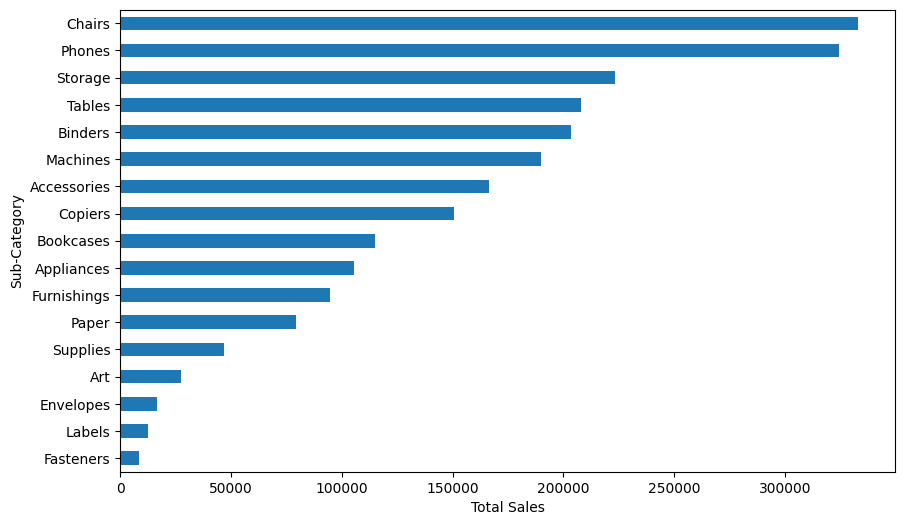

In [35]:
# bar chart: sales by sub-category

plt.figure(figsize=(10,6))
df.groupby('Sub-Category')['Sales'].sum().sort_values().plot(kind='barh')
plt.xlabel('Total Sales')
plt.ylabel('Sub-Category')
plt.show()

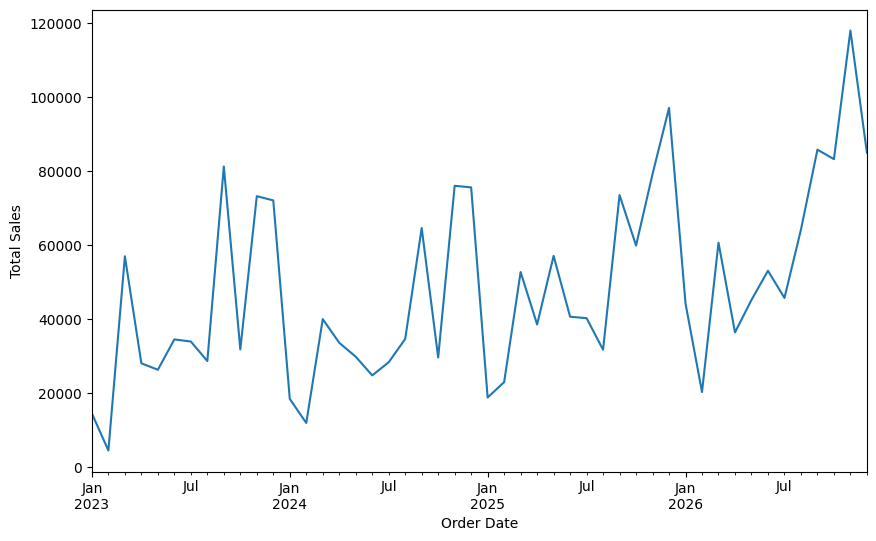

In [36]:
# line chart: monthly sales trend

plt.figure(figsize=(10,6))
monthly = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()
monthly.plot(kind='line')
plt.xlabel('Order Date')
plt.ylabel('Total Sales')
plt.show()

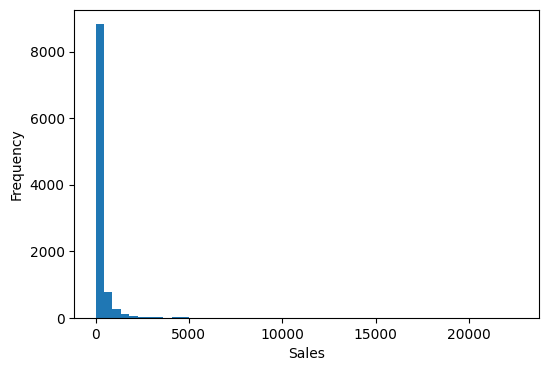

In [42]:
# histogram: distribution of order values

plt.figure(figsize=(6,4))
df['Sales'].plot(kind='hist', bins=50)
plt.xlabel('Sales')
plt.show()